# Nasdaq 02 · Channel-breakout momentum on Nasdaq stocks

This re-runs the ASX channel-breakout research on **Nasdaq-listed stocks** (the 1,000 most traded each month). Run `01_data_and_universe.ipynb` first.

**Why Nasdaq is a useful third test.** The S&P 1500 test (`../us_sp1500/`) found no edge in US stocks. Nasdaq is still the US market, but its mix is closer to the ASX 500's: many smaller, volatile, story-driven growth, tech and biotech stocks, where trends could plausibly persist the way resource stocks' do on the ASX.

**The rule is imported unchanged** from the ASX study (N=250 entry, M=125 exit, next-day fill, 20 bps). A horizon sweep is shown for context only. A **top-100 subset** approximates the Nasdaq-100.

**Contents**
1. Signal and backtest engine (identical to the ASX study)
2. Benchmarks
3. Time horizon
4. The ASX rule on Nasdaq stocks (plus a Nasdaq-100-like subset)
5. Costs
6. Legs and calendar years
7. Size control
8. Statistical tests vs random buy-and-hold
9. ASX vs S&P 1500 vs Nasdaq
10. Conclusions

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import kurtosis, norm, skew

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
TRADING_DAYS = 252
IS, OOS = slice("2006-01-01", "2016-12-31"), slice("2017-01-01", None)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a8a"
BLUE_LIGHT, BLUE_MID = "#cde2fb", "#86b6ef"

d = pd.read_pickle("data/clean.pkl")
spx = d["bench_ret"]["^IXIC"]     # benchmark (variable name kept from the US notebook)
ndx = d["bench_ret"]["^NDX"]      # hedge instrument (Nasdaq-100 futures)
N, M = 250, 125          # the ASX rule, not re-optimised
print(f"{d['adj'].shape[1]} stocks, {d['adj'].index[0]:%Y-%m-%d} to {d['adj'].index[-1]:%Y-%m-%d}")

3154 stocks, 2005-01-03 to 2026-10-09


## 1. Signal and backtest engine

The code is unchanged from the ASX study:
* **Donchian state:** go long when the close breaks above the prior N-day high and exit below the prior M-day low; the short side is the mirror image. Positions are forced flat outside the universe.
* **Drift engine:** the long side holds +0.5 of capital and the short side −0.5. A new entry gets an equal share of its side, then positions drift with price, and every trade is charged.
* **Execution:** signals from day *t*'s close are traded at day *t+1*'s close (`lag=2`).

In [2]:
def channels(d, n):
    return (d["high"].rolling(n, min_periods=n).max().shift(1),
            d["low"].rolling(n, min_periods=n).min().shift(1))


def donchian_state(d, n, m=None):
    m = m or max(n // 2, 2)
    px, member = d["adj"], d["member"]
    up_n, lo_n = channels(d, n)
    up_m, lo_m = channels(d, m)

    def state(enter, leave):
        s = pd.DataFrame(np.nan, index=px.index, columns=px.columns)
        return s.mask(leave | ~member, 0.0).mask(enter & member, 1.0).ffill().fillna(0.0)

    return state(px > up_n, px < lo_m) - state(px < lo_n, px > up_m)


def backtest_drift(signal, d, scheme="neutral", cost_bps=20, lag=2, scale=None):
    sig = np.sign(signal.shift(lag - 1).fillna(0.0)).values if lag > 1 else np.sign(signal.fillna(0.0)).values
    r = d["ret"].reindex_like(signal).fillna(0.0).values
    k = np.ones(len(sig)) if scale is None else scale.reindex(signal.index).fillna(0.0).values
    sides = [(1, 0.5), (-1, 0.5)] if scheme == "neutral" else [(1, 1.0)]
    h = np.zeros(sig.shape[1])
    gross, turn = np.zeros(len(sig)), np.zeros(len(sig))
    for t in range(len(sig)):
        if t:
            pnl = h @ r[t]
            gross[t] = pnl
            h = h * (1 + r[t]) / (1 + pnl)
        new = np.zeros_like(h)
        for side, g in sides:
            g = g * k[t]
            on = sig[t] == side
            if not on.any() or g == 0:
                continue
            keep = on & (np.sign(h) == side) & (h != 0)
            enter = on & ~keep
            w_enter = g / on.sum()
            rest = g - w_enter * enter.sum()
            held = np.abs(h[keep]).sum()
            new[enter] = side * w_enter
            if keep.any():
                new[keep] = h[keep] * (rest / held if held > 0 else 0)
        turn[t] = np.abs(new - h).sum()
        h = new
    gross, turn = pd.Series(gross, signal.index), pd.Series(turn, signal.index)
    return pd.DataFrame({"gross": gross, "net": gross - turn * cost_bps / 1e4, "turnover": turn})


def stats(r, bench=None):
    r = r.dropna()
    ann_ret, ann_vol = r.mean() * TRADING_DAYS, r.std() * np.sqrt(TRADING_DAYS)
    eq = (1 + r).cumprod()
    out = {"ann_ret": ann_ret, "ann_vol": ann_vol, "sharpe": ann_ret / ann_vol, "max_dd": (eq / eq.cummax() - 1).min()}
    if bench is not None:
        b = bench.reindex(r.index).fillna(0.0)
        fit = sm.OLS(r, sm.add_constant(b)).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        out.update(alpha=fit.params["const"] * TRADING_DAYS, alpha_t=fit.tvalues["const"], beta=fit.params.iloc[1])
    return pd.Series(out)


def report(series, bench, periods=(("IS", IS), ("OOS", OOS))):
    return pd.DataFrame({(name, per): stats(sr.loc[sl], bench) for name, sr in series.items() for per, sl in periods}).T

## 2. Benchmarks

* **Nasdaq Composite (^IXIC):** the broad reference, used for beta. It is a price index (no dividends), like ^AXJO in the ASX study.
* **Equal-weight universe, drifting:** members are held with drifting weights and carry the same survivorship bias as the strategy. Alpha is measured against it.

In [3]:
ew = backtest_drift(d["member"].astype(float), d, "long", cost_bps=0, lag=1)["net"]
bench_table = pd.concat([report({"EW universe": ew}, spx), report({"Nasdaq Composite": spx}, None)])
bench_table.to_csv(RESULTS / "01_benchmark.csv")
bench_table[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "beta"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  beta
EW universe      IS     0.087    0.212   0.410  -0.607 -0.011 0.933
                 OOS    0.110    0.252   0.435  -0.511 -0.082 1.000
Nasdaq Composite IS     0.105    0.216   0.484  -0.556    NaN   NaN
                 OOS    0.192    0.223   0.859  -0.364    NaN   NaN

## 3. Time horizon (context only)

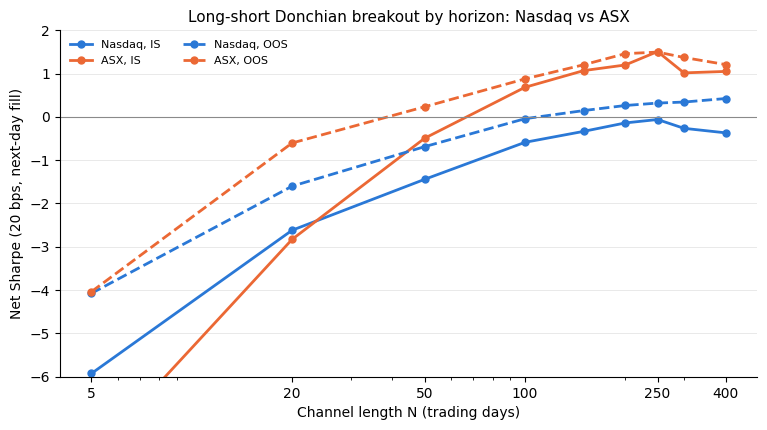

lag         1             2       
period     IS    OOS     IS    OOS
N                                 
5      -8.250 -4.020 -5.930 -4.070
20     -3.420 -1.710 -2.620 -1.600
50     -1.850 -0.780 -1.440 -0.690
100    -0.840 -0.100 -0.590 -0.040
150    -0.490  0.080 -0.340  0.140
200    -0.240  0.230 -0.140  0.260
250    -0.150  0.280 -0.060  0.320
300    -0.380  0.310 -0.260  0.340
400    -0.400  0.440 -0.370  0.420

In [4]:
rows = {}
for n in [5, 20, 50, 100, 150, 200, 250, 300, 400]:
    s_n = donchian_state(d, n)
    for lag in [1, 2]:
        bt = backtest_drift(s_n, d, "neutral", 20, lag)
        for per, sl in [("IS", IS), ("OOS", OOS)]:
            rows[(n, lag, per)] = stats(bt["net"].loc[sl], ew)
horizon = pd.DataFrame(rows).T.rename_axis(["N", "lag", "period"])
horizon.to_csv(RESULTS / "02_horizon_sweep.csv")

asx_h = pd.read_csv("../results/02_horizon_sweep.csv").set_index(["N", "lag", "period"])["sharpe"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for per, ls in [("IS", "-"), ("OOS", "--")]:
    us = horizon.xs((2, per), level=("lag", "period"))["sharpe"]
    asx = asx_h.xs((2, per), level=("lag", "period")).reindex(us.index)
    ax.plot(us.index, us.values, color=BLUE, ls=ls, marker="o", ms=5, lw=2, label=f"Nasdaq, {per}")
    ax.plot(asx.index, asx.values, color=ORANGE, ls=ls, marker="o", ms=5, lw=2, label=f"ASX, {per}")
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xscale("log")
ax.set_xticks([5, 20, 50, 100, 250, 400], labels=[5, 20, 50, 100, 250, 400])
ax.set_ylim(-6, 2)
ax.set_xlabel("Channel length N (trading days)")
ax.set_ylabel("Net Sharpe (20 bps, next-day fill)")
ax.set_title("Long-short Donchian breakout by horizon: Nasdaq vs ASX", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False, ncol=2)
fig.savefig(RESULTS / "horizon_nasdaq_vs_asx.png", dpi=130, bbox_inches="tight")
plt.show()
horizon["sharpe"].unstack(["lag", "period"]).round(2)

### Reading the sweep

* **Short horizons reverse,** as in every market tested.
* **Long-horizon momentum is weak but present after 2016.** In-sample (2006–2016) the Sharpe is at or below zero at every horizon. Out-of-sample it is positive from N=150 and rises with the channel length (0.32 at N=250, 0.42 at N=400). That is between the S&P 1500 (about zero) and the ASX (about 1.5).
* **Next-day execution helps a little** (lag 2 vs lag 1), more than for the S&P 1500 but less than on the ASX. That fits Nasdaq's larger share of small, less liquid stocks.

## 4. The ASX rule on Nasdaq stocks

N=250, M=125, next-day fill, 20 bps, with the same variants as the ASX study:

| Variant | Description |
|---|---|
| L/S, all names | longs and shorts across the whole universe |
| L/S, shorts in top 400 | shorts only in the 400 most liquid names (the same 40% share as the ASX top-200-of-500 restriction) |
| Long-only | breakout longs, fully invested |
| Long-only, Nasdaq-100 hedge | long book minus rolling 126-day beta × Nasdaq-100; in practice, short Nasdaq-100 (NQ) futures |
| Top-100 L/S and long-only | the same rule inside the 100 most-traded names each month, roughly the Nasdaq-100 |
| L/S, 10% vol target | the L/S book scaled to 10% annualised volatility |

In [5]:
s = donchian_state(d, N, M)
rank = d["adv"].where(d["member"]).rank(axis=1, ascending=False)
top500 = (rank <= 400).shift(1, fill_value=False)      # top 400 (variable name kept from the US notebook)
s_top = s.where((s > 0) | top500, 0.0)
top100 = (rank <= 100).shift(1, fill_value=False)
d100 = dict(d, member=d["member"] & top100)
s100 = donchian_state(d100, N, M)

books = {
    "L/S, all names": backtest_drift(s, d, "neutral", 20, 2)["net"],
    "L/S, shorts in top 400": backtest_drift(s_top, d, "neutral", 20, 2)["net"],
    "Long-only": backtest_drift(s, d, "long", 20, 2)["net"],
}
books["Top-100 L/S"] = backtest_drift(s100, d100, "neutral", 20, 2)["net"]
books["Top-100 long-only"] = backtest_drift(s100, d100, "long", 20, 2)["net"]
lo, m = books["Long-only"], ndx.fillna(0.0)
cov = (lo * m).rolling(126, min_periods=60).mean() - lo.rolling(126, min_periods=60).mean() * m.rolling(126, min_periods=60).mean()
hb = (cov / m.rolling(126, min_periods=60).var()).shift(1).fillna(1.0)
books["Long-only, Nasdaq-100 hedge"] = lo - hb * m - hb.diff().abs().fillna(0) * 2e-4
r_ls = books["L/S, all names"]
scale = (0.10 / (r_ls.rolling(63).std() * np.sqrt(TRADING_DAYS))).shift(1).clip(upper=3).fillna(0)
books["L/S, 10% vol target"] = backtest_drift(s, d, "neutral", 20, 2, scale=scale)["net"]

periods = (("IS", IS), ("OOS", OOS), ("FULL", slice("2006-01-01", None)))
final = report(books, ew, periods).join(report(books, spx, periods)[["alpha", "alpha_t", "beta"]].add_suffix("_spx"))
final.to_csv(RESULTS / "05_final_strategies.csv")
final[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "alpha_spx", "beta_spx"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t  alpha_spx  beta_spx
L/S, all names              IS     -0.003    0.052  -0.061  -0.242 -0.002   -0.103     -0.002    -0.009
                            OOS     0.028    0.089   0.318  -0.140  0.031    1.241      0.030    -0.010
                            FULL    0.012    0.072   0.162  -0.242  0.014    0.933      0.013    -0.009
L/S, shorts in top 400      IS     -0.015    0.060  -0.257  -0.299 -0.007   -0.369     -0.005    -0.099
                            OOS     0.000    0.095   0.003  -0.199  0.001    0.030      0.004    -0.021
                            FULL   -0.008    0.078  -0.102  -0.399 -0.003   -0.211      0.001    -0.061
Long-only                   IS      0.064    0.211   0.304  -0.615 -0.020   -1.165     -0.030     0.905
                            OOS     0.141    0.232   0.609  -0.410  0.045    2.104     -0.029     0.886
                            FULL    0.100    0.221   0.454  -0.615  0.011    0.826     -0.030     0.896
Top-100 L/S                 IS     -0.016    0.087  -0.179  -0.401 -0.007   -0.273     -0.005    -0.099
                            OOS     0.002    0.132   0.013  -0.311  0.000    0.010     -0.002     0.018
                            FULL   -0.007    0.110  -0.067  -0.543 -0.004   -0.156     -0.001    -0.042
Top-100 long-only           IS      0.071    0.207   0.345  -0.568  0.001    0.029     -0.016     0.830
                            OOS     0.227    0.265   0.856  -0.382  0.128    3.151      0.031     1.021
                            FULL    0.145    0.236   0.612  -0.568  0.061    2.392      0.010     0.923
Long-only, Nasdaq-100 hedge IS     -0.052    0.101  -0.509  -0.611 -0.068   -2.485     -0.061     0.086
                            OOS    -0.045    0.130  -0.349  -0.464 -0.070   -1.871     -0.052     0.037
                            FULL   -0.049    0.115  -0.421  -0.733 -0.069   -3.019     -0.058     0.062
L/S, 10% vol target         IS      0.018    0.104   0.169  -0.272  0.019    0.564      0.017     0.003
                            OOS     0.042    0.107   0.392  -0.138  0.046    1.492      0.044    -0.013
                            FULL    0.029    0.105   0.275  -0.272  0.032    1.397      0.030    -0.005

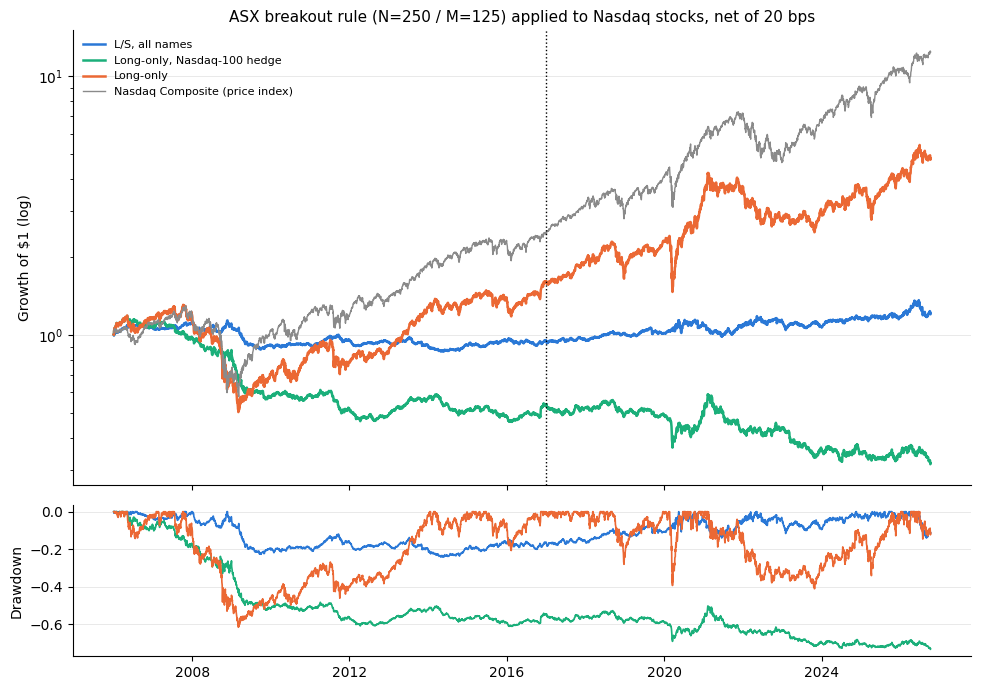

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for name, c in zip(["L/S, all names", "Long-only, Nasdaq-100 hedge", "Long-only"], [BLUE, AQUA, ORANGE]):
    eq = (1 + books[name].loc["2006":]).cumprod()
    axs[0].plot(eq, color=c, lw=1.8, label=name)
    axs[1].plot(eq / eq.cummax() - 1, color=c, lw=1.2)
axs[0].plot((1 + spx.loc["2006":].fillna(0)).cumprod(), color=GREY, lw=1, label="Nasdaq Composite (price index)")
axs[0].axvline(pd.Timestamp("2017-01-01"), color="k", ls=":", lw=1)
axs[0].set_yscale("log")
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].set_title("ASX breakout rule (N=250 / M=125) applied to Nasdaq stocks, net of 20 bps", fontsize=11)
axs[0].legend(fontsize=8, frameon=False)
axs[1].set_ylabel("Drawdown")
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
fig.tight_layout()
fig.savefig(RESULTS / "equity_curves.png", dpi=130)
plt.show()

### Reading the results

* **The L/S book has no reliable edge.** Sharpe −0.06 in-sample and 0.32 out-of-sample, with out-of-sample alpha of 3.1% that is not significant (t = 1.2). It loses less than in the S&P 1500 but is far from the ASX's 1.5.
* **Long-only beats the equal-weight universe out-of-sample** (alpha 4.5%, t = 2.1) but **trails the cap-weighted Nasdaq Composite** (−2.9%/yr). 2017–2026 was dominated by a handful of mega-cap tech stocks: the equal-weight universe returned 11% a year against 19% for the Composite.
* **Hedging with the Nasdaq-100 backfired** (Sharpe −0.35 out-of-sample, alpha −7%). The hedge shorts exactly the mega-caps that led the market, while the long book holds mostly smaller stocks. An index hedge only works when the index resembles the book.
* **The top-100 subset** (roughly the Nasdaq-100) has no L/S edge either (Sharpe ≈ 0). Its long-only book shows a large alpha against the equal-weight universe (12.8%, t = 3.2), but that compares the biggest stocks with the whole universe during a mega-cap boom. Against the Nasdaq Composite its alpha is only 3.1% with beta 1.0, so most of that "alpha" is size, not breakout timing.
* **Costs are not the problem.** Even at 0 bps the out-of-sample Sharpe is only 0.48 (alpha t = 1.8).

## 5. Costs

Nasdaq stocks trade at a 1-cent tick, so for the larger names realistic all-in costs are well below the brief's 20 bps; thinly traded small caps cost more. Shown for the L/S book: 0, 5, 20 (brief) and 50 bps.

In [7]:
costs = report({f"{c} bps": backtest_drift(s, d, "neutral", c, 2)["net"] for c in [0, 5, 20, 50]}, ew)
costs.to_csv(RESULTS / "06_costs.csv")
costs[["sharpe", "alpha", "alpha_t"]].unstack().round(3)

sharpe        alpha       alpha_t      
           IS   OOS     IS   OOS      IS   OOS
0 bps   0.197 0.477  0.012 0.045   0.706 1.810
20 bps -0.061 0.318 -0.002 0.031  -0.103 1.241
5 bps   0.133 0.437  0.008 0.042   0.504 1.668
50 bps -0.449 0.080 -0.022 0.010  -1.315 0.390

## 6. Legs and calendar years

In [8]:
legs = {"L/S": r_ls,
        "long leg": backtest_drift(s.clip(lower=0), d, "neutral", 20, 2)["net"],
        "short leg": backtest_drift(s.clip(upper=0), d, "neutral", 20, 2)["net"],
        "EW universe": ew, "Nasdaq Composite": spx}
yearly = pd.DataFrame(legs).loc["2006":].fillna(0)
yearly = yearly.groupby(yearly.index.year).apply(lambda x: (1 + x).prod() - 1)
yearly.to_csv(RESULTS / "07_yearly.csv")
print(f"L/S positive full years: {(yearly.loc[:2025, 'L/S'] > 0).sum()} of {len(yearly.loc[:2025])}")
yearly.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4, subset=["L/S", "long leg", "short leg"])

L/S positive full years: 14 of 20


,L/S,long leg,short leg,EW universe,Nasdaq Composite
date,,,,,
2006,6.3%,7.9%,-1.9%,16.4%,9.5%
2007,4.9%,1.8%,2.3%,1.6%,9.8%
2008,-1.4%,-20.6%,19.9%,-41.2%,-40.5%
2009,-17.8%,-1.0%,-18.5%,29.3%,43.9%
2010,0.8%,11.5%,-10.4%,22.5%,16.9%
2011,4.8%,-3.9%,7.3%,-7.4%,-1.8%
2012,-1.7%,5.2%,-7.0%,14.5%,15.9%
2013,-3.1%,22.2%,-21.0%,48.1%,38.3%
2014,0.3%,3.5%,-3.5%,8.6%,13.4%


## 7. Size control

A second factor is added to the alpha regression: the equal-weight universe minus the equal-weight 400 most liquid names, both drifting.

In [9]:
ew500 = backtest_drift((d["member"] & top500).astype(float), d, "long", cost_bps=0, lag=1)["net"]
factors = pd.DataFrame({"ew": ew, "size": ew - ew500})
rows = {}
for name in ["L/S, all names", "L/S, shorts in top 400"]:
    for per, sl in [("IS", IS), ("OOS", OOS)]:
        fit = sm.OLS(books[name].loc[sl], sm.add_constant(factors.loc[sl].fillna(0))).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        rows[(name, per)] = {"alpha": fit.params["const"] * TRADING_DAYS, "alpha_t": fit.tvalues["const"],
                             "beta_ew": fit.params["ew"], "beta_size": fit.params["size"]}
size_ctrl = pd.DataFrame(rows).T
size_ctrl.to_csv(RESULTS / "09_size_control.csv")
size_ctrl

alpha  alpha_t  beta_ew  beta_size
L/S, all names         IS  -0.001   -0.090   -0.050     -0.228
                       OOS  0.006    0.275   -0.046     -0.605
L/S, shorts in top 400 IS  -0.007   -0.386   -0.070      0.214
                       OOS -0.010   -0.369   -0.015     -0.270

## 8. Statistical tests vs random buy-and-hold

These are the same tests as in the ASX study (section 13 there):
* **Monte Carlo:** 1,000 random equal-weight buy-and-hold portfolios with the same number of names as the strategy's average long book.
* **Timing permutation:** each stock's signal is shifted by a random amount of time, keeping its trade count and holding periods. 100 permutations, so the p-value floor is about 0.01.
* **Paired block bootstrap:** stationary bootstrap, mean block 20 days, 2,000 resamples, testing the Sharpe difference against the median random portfolio.
* **Probabilistic Sharpe ratio:** because the rule was imported unchanged from the ASX, there was no search on US data. The plain PSR (hurdle 0) is therefore the right test for the *full* US sample, not just out-of-sample.

In [10]:
def ann_sharpe(x, axis=0):
    return x.mean(axis) / x.std(axis) * np.sqrt(TRADING_DAYS)


def psr(r):
    r = r.dropna()
    sr = r.mean() / r.std()
    z = sr * np.sqrt(len(r) - 1) / np.sqrt(1 - skew(r) * sr + (kurtosis(r, fisher=False) - 1) / 4 * sr ** 2)
    return norm.cdf(z)


def stationary_bootstrap_idx(T, B, mean_block, rng):
    idx = np.empty((B, T), dtype=np.int64)
    idx[:, 0] = rng.integers(0, T, B)
    jump = rng.random((B, T)) < 1 / mean_block
    fresh = rng.integers(0, T, (B, T))
    for t in range(1, T):
        idx[:, t] = np.where(jump[:, t], fresh[:, t], (idx[:, t - 1] + 1) % T)
    return idx


rng = np.random.default_rng(7)
ret0 = d["ret"].fillna(0.0)
k_match = int(round((s > 0).sum(axis=1).loc["2006":].mean()))
tested = {"Long-only": books["Long-only"], "L/S, all names": r_ls, "Long-only, Nasdaq-100 hedge": books["Long-only, Nasdaq-100 hedge"]}
rows = {}
for wname, start in [("FULL 2006-", "2006-01-03"), ("OOS 2017-", "2017-01-03")]:
    r_win = ret0.loc[start:]
    pool = np.flatnonzero(d["member"].loc[start:].iloc[0].values)
    growth = np.cumprod(1 + r_win.values, axis=0)
    picks = np.array([rng.choice(pool, k_match, replace=False) for _ in range(1000)])
    value = growth[:, picks].mean(axis=2) * (1 - 20e-4)
    rand = np.vstack([value[:1] - 1, value[1:] / value[:-1] - 1])
    rand_sh = ann_sharpe(rand)
    idx = stationary_bootstrap_idx(len(r_win), 2000, 20, rng)
    sub = rand[:, :200]
    for name, sr in tested.items():
        x = sr.loc[start:].values
        diffs = np.array([ann_sharpe(x[row]) - np.median(ann_sharpe(sub[row])) for row in idx])
        rows[(wname, name)] = {
            "Sharpe": ann_sharpe(x), "random B&H median Sharpe": np.median(rand_sh),
            "MC p (Sharpe)": (1 + (rand_sh >= ann_sharpe(x)).sum()) / 1001,
            "bootstrap ΔSharpe": ann_sharpe(x) - np.median(ann_sharpe(sub)),
            "ΔSharpe CI low": np.percentile(diffs, 2.5), "ΔSharpe CI high": np.percentile(diffs, 97.5),
            "bootstrap p": max(2 * min((diffs <= 0).mean(), (diffs >= 0).mean()), 1 / 2000),
            "PSR (Sharpe > 0)": psr(sr.loc[start:])}
tests = pd.DataFrame(rows).T
print(f"random portfolios hold K={k_match} names")
tests

random portfolios hold K=383 names


Sharpe  random B&H median Sharpe  MC p (Sharpe)  bootstrap ΔSharpe  ΔSharpe CI low  ΔSharpe CI high  bootstrap p  PSR (Sharpe > 0)
FULL 2006- Long-only                     0.454                     0.528          1.000             -0.075          -0.237            0.079        0.350             0.980
           L/S, all names                0.162                     0.528          1.000             -0.367          -1.005            0.272        0.248             0.769
           Long-only, Nasdaq-100 hedge  -0.421                     0.528          1.000             -0.950          -1.428           -0.528        0.001             0.028
OOS 2017-  Long-only                     0.609                     0.581          0.199              0.028          -0.154            0.205        0.787             0.970
           L/S, all names                0.318                     0.581          1.000             -0.263          -1.106            0.583        0.563             0.838
           Long-only, Nasdaq-100 hedge  -0.349                     0.581          1.000             -0.930          -1.544           -0.350        0.003             0.138

In [11]:
prng = np.random.default_rng(5)
mem, sv0 = d["member"].values, s.values
T, n_cols = sv0.shape
perm = {"Long-only": [], "L/S, all names": []}
for _ in range(100):
    shifts = prng.integers(252, T - 252, n_cols)
    rows_idx = (np.arange(T)[:, None] - shifts[None, :]) % T
    sp = pd.DataFrame(np.where(mem, sv0[rows_idx, np.arange(n_cols)], 0.0), s.index, s.columns)
    perm["Long-only"].append(stats(backtest_drift(sp, d, "long", 20, 2)["net"].loc["2006":])["sharpe"])
    perm["L/S, all names"].append(stats(backtest_drift(sp, d, "neutral", 20, 2)["net"].loc["2006":])["sharpe"])
perm_table = pd.DataFrame({name: {"observed Sharpe": stats(tested[name].loc["2006":])["sharpe"],
                                  "null median": np.median(v), "null p95": np.percentile(v, 95),
                                  "p-value": (1 + (np.array(v) >= stats(tested[name].loc["2006":])["sharpe"]).sum()) / 101}
                           for name, v in perm.items()}).T
tests.to_csv(RESULTS / "11_significance.csv")
perm_table.to_csv(RESULTS / "11b_permutation.csv")
perm_table

,observed Sharpe,null median,null p95,p-value
Long-only,0.454,0.547,0.578,1.000
"L/S, all names",0.162,-0.497,-0.229,0.010


### Reading the tests

* **No book is significantly different from random buy-and-hold** on Sharpe once time-sampling noise is included (bootstrap p = 0.25–0.79), except the Nasdaq-100-hedged book, which is significantly *worse*.
* **Timing permutation:** real breakout timing beats random timing for the L/S book (p = 0.01), but again against a null that loses money (median Sharpe −0.5).
* **PSR:** the L/S out-of-sample Sharpe of 0.32 is above zero with probability 0.84, which is not significant.

### Cross-check: classic 12-1 momentum in all three markets

As an independent check, compare with classic **12-1 momentum** (Jegadeesh & Titman): each month, rank stocks on their return from 12 months ago to 1 month ago, buy the top decile and sell the bottom decile, equal weight, for one month. It is run on both datasets with the same code.

In [12]:
def classic_momentum(path):
    dd = pd.read_pickle(path)
    me = dd["adj"].ffill(limit=5).resample("ME").last()
    mem = dd["member"].resample("ME").last()
    mret = me.pct_change(fill_method=None)
    mom = (me.shift(1) / me.shift(12) - 1).where(mem)
    out = {}
    for t in range(13, len(me) - 1):
        sc = mom.iloc[t].dropna()
        if len(sc) < 100:
            continue
        q, nxt = sc.rank(pct=True), mret.iloc[t + 1]
        win, lose = nxt[q[q > 0.9].index].mean(), nxt[q[q < 0.1].index].mean()
        out[me.index[t + 1]] = {"winners - losers": win - lose, "winners - all": win - nxt[sc.index].mean()}
    return pd.DataFrame(out).T.fillna(0)


rows = {}
for mkt, path in [("Nasdaq", "data/clean.pkl"), ("S&P 1500", "../us_sp1500/data/clean.pkl"), ("ASX", "../data/clean.pkl")]:
    cm = classic_momentum(path)
    for per, sl in [("IS", IS), ("OOS", OOS)]:
        x = cm.loc[sl]
        for col in x:
            rows[(mkt, per, col)] = {"ann_ret": x[col].mean() * 12, "sharpe": x[col].mean() / x[col].std() * np.sqrt(12)}
classic = pd.DataFrame(rows).T
classic.to_csv(RESULTS / "10_classic_momentum_check.csv")
classic["sharpe"].unstack(1).round(2)

IS   OOS
ASX      winners - all     0.830 0.710
         winners - losers  0.590 1.110
Nasdaq   winners - all     0.040 0.460
         winners - losers -0.020 0.660
S&P 1500 winners - all    -0.170 0.720
         winners - losers -0.200 0.330

### Reading the check

Classic 12-1 momentum agrees with the breakout results in all three markets:

* **ASX:** strong in both periods.
* **Nasdaq and S&P 1500:** about zero or negative in 2006–2016, then positive in 2017–2026 (Nasdaq winners minus losers Sharpe 0.66, S&P 1500 0.33).

US momentum came back after 2016 in both US universes. Nasdaq, with its smaller and more volatile growth stocks, shows the stronger revival, but even there it is roughly half the ASX level.

## 9. ASX vs S&P 1500 vs Nasdaq

Same rule, same costs, same engine. Alpha is against each market's own drifting equal-weight universe.

In [13]:
asx = pd.read_csv("../results/05_final_strategies.csv", index_col=[0, 1])
us = pd.read_csv("../us_sp1500/results/05_final_strategies.csv", index_col=[0, 1])
cols = ["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t"]
pairs = {"L/S, all names": [("ASX", asx, "Research L/S (all 500)"), ("S&P 1500", us, "L/S, all names"), ("Nasdaq", final, "L/S, all names")],
         "Long-only": [("ASX", asx, "Long-only"), ("S&P 1500", us, "Long-only"), ("Nasdaq", final, "Long-only")]}
rows = {}
for book, srcs in pairs.items():
    for per in ["IS", "OOS"]:
        for mkt, src, name in srcs:
            rows[(book, per, mkt)] = src.loc[(name, per), cols]
side = pd.DataFrame(rows).T
side.to_csv(RESULTS / "12_three_markets.csv")
side.style.format({"ann_ret": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}",
                   "alpha": "{:.1%}", "alpha_t": "{:.1f}"})

## 10. Conclusions

1. **Nasdaq sits between the ASX and the S&P 1500, much closer to the S&P 1500.** The unchanged ASX rule earns a market-neutral Sharpe of −0.06 in 2006–2016 and 0.32 in 2017–2026, against 1.5 / 1.5 on the ASX and −0.57 / −0.01 on the S&P 1500. The out-of-sample alpha (3.1%) is not significant.
2. **The improvement after 2016 is a US-wide momentum revival, not a Nasdaq-specific edge.** Classic 12-1 momentum shows the same timing in both US universes.
3. **Beware benchmark choice in a mega-cap era.** The long-only and top-100 books look good against an equal-weight benchmark but not against the cap-weighted Nasdaq Composite. Hedging small and mid caps with Nasdaq-100 futures lost money because the hedge was short the market leaders.
4. **Short horizons reverse** here too, consistent across all four studies (ASX daily, ASX intraday, S&P 1500, Nasdaq).
5. **The ASX remains the outlier.** Of three markets, only the ASX shows a strong, persistent, significant breakout-momentum edge. That fits the idea that the effect lives in less-arbitraged, small-cap, resource-heavy markets, but it also means the ASX result should be treated as market-specific rather than a general law.

**Caveats:** survivorship bias is large (today's Nasdaq listings only; Nasdaq delists more companies than most exchanges); the pool includes some SPACs, which trade flat near \$10 and rarely break out; and the Nasdaq Composite and Nasdaq-100 are price indices without dividends.